In [ ]:
# Importing necessary library.

In [63]:
import numpy as np
import pandas as pd

In [4]:
# uploading placement dataset

In [64]:
df = pd.read_csv("placement.csv")

In [65]:
# overview of the dataset.

In [99]:
df.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


In [6]:
# from here we can see that there is a cloumn named as "unnamed" which is not necessary for us.

In [8]:
# to known the shape
df.shape

(100, 4)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  100 non-null    int64  
 1   cgpa        100 non-null    float64
 2   iq          100 non-null    float64
 3   placement   100 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 3.3 KB


In [67]:
# remove unnecessary column
df = df.iloc[:, 1:]

In [96]:
df.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


In [68]:
# EXPLORATORY DATA ANALYSIS

import matplotlib.pyplot as plt

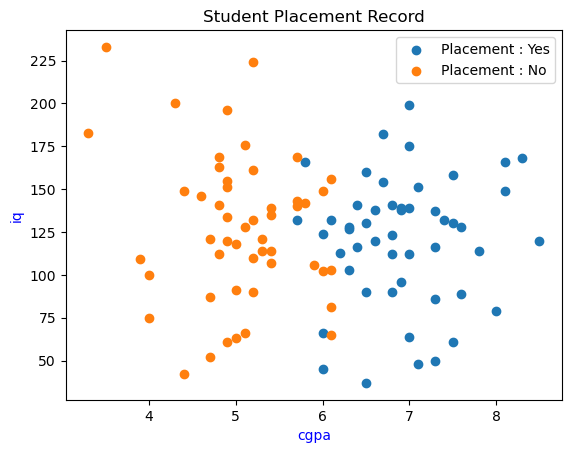

In [69]:
plt.scatter(df[df['placement'] == 1]['cgpa'],
           df[df['placement'] == 1]['iq'], label = "Placement : Yes")

plt.scatter(df[df['placement'] == 0]['cgpa'],
           df[df['placement'] == 0]['iq'], label = 'Placement : No')
plt.legend()
plt.title("Student Placement Record")
plt.xlabel("cgpa",c = 'b')
plt.ylabel("iq", c = 'b')
plt.show()

In [70]:
# creating independent and dependent column

x = df.iloc[:, 0:2]

y = df.iloc[:, -1]

x.head()

,cgpa,iq
0,6.8,123.0
1,5.9,106.0
2,5.3,121.0
3,7.4,132.0
4,5.8,142.0


In [45]:
y.head()

0    1
1    0
2    0
3    1
4    0
Name: placement, dtype: int64

In [48]:
x.shape

(100, 2)

In [47]:
y.shape

(100,)

In [71]:
from sklearn.model_selection import train_test_split as tts

x_train, x_test,y_train, y_test = tts(x, y, test_size = 0.1)

In [72]:
x_train.shape

(90, 2)

In [73]:
x_test.shape

(10, 2)

In [74]:
y_train.shape

(90,)

In [75]:
y_test.shape

(10,)

# Scaling

In [80]:
# library for scaling
from sklearn.preprocessing import StandardScaler as ss

scaler = ss()

x_train = scaler.fit_transform(x_train)

In [81]:
x_train

array([[ 0.95305246, -1.89491971],
       [ 1.5564927 , -0.20663066],
       [-1.02967979,  0.48403304],
       [-0.51244529, -0.20663066],
       [-0.25382804,  1.20027688],
       [ 0.43581796, -2.17630122],
       [ 0.26340646,  0.12591112],
       [-0.25382804,  0.53519331],
       [ 0.26340646, -0.48801217],
       [ 0.09099496, -1.05077519],
       [ 0.86684671, -0.25779094],
       [ 2.15993295, -0.05314984],
       [-0.51244529,  0.43287276],
       [ 0.60822946,  1.53281866],
       [-0.59865104, -0.0275697 ],
       [ 0.95305246,  0.73983441],
       [ 0.86684671,  0.43287276],
       [-1.80553154, -0.33453135],
       [-1.46070854,  1.99326113],
       [-1.11588554, -0.0275697 ],
       [ 0.69443521, -0.82055395],
       [ 1.81510995,  0.68867414],
       [ 0.69443521,  0.48403304],
       [-0.94347404, -1.56237793],
       [ 0.09099496, -0.48801217],
       [-1.71932579, -1.20425601],
       [ 0.26340646,  0.15149126],
       [-0.59865104, -0.20663066],
       [-0.94347404,

In [82]:
x_test = scaler.transform(x_test)

In [83]:
x_test

array([[-0.68485679,  0.2538118 ],
       [-0.68485679, -0.30895121],
       [-0.85726829, -1.51121766],
       [-0.94347404,  1.89094058],
       [ 0.86684671,  1.96768099],
       [ 0.43581796, -0.82055395],
       [ 0.17720071, -0.2322108 ],
       [-0.68485679,  0.99563578],
       [ 1.2116697 ,  0.2538118 ],
       [ 0.86684671,  1.3537577 ]])

# Train the Model

In [84]:
from sklearn.linear_model import LogisticRegression

In [85]:
clf = LogisticRegression()

In [86]:
clf.fit(x_train, y_train)

LogisticRegression()

# Evaluate the Model.

In [89]:
y_pred = clf.predict(x_test)

In [88]:
y_test

19    0
92    0
7     0
80    0
26    1
79    1
99    1
47    0
3     1
52    1
Name: placement, dtype: int64

In [91]:
from sklearn.metrics import accuracy_score 

In [92]:
accuracy_score(y_test, y_pred)

1.0

# Decision Making

In [105]:
from mlxtend.plotting import plot_decision_regions

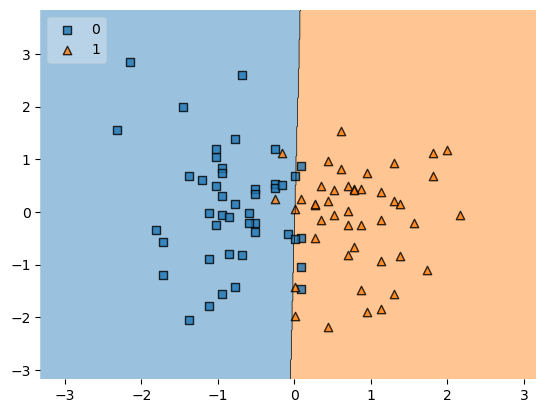

In [107]:
plot_decision_regions(x_train, y_train.values, clf=clf, legend=2)
plt.show()

In [108]:
import pickle

In [109]:
pickle.dump(clf, open("model.pkl", 'wb'))